# 2D segmentation workflow figure · `3.cell_segmentation/notebooks`

Draws a publication-ready workflow schematic of the 2D segmentation module of
**NF1_2D_organoid_profiling_pipeline** from matplotlib patches only (rounded cards,
accent bars, polyline arrows), so every element stays vector and editable.

| Panel | Source |
|---|---|
| Nuclei | `0.segment_nuclei.ipynb`: CLAHE (clip 0.02) on 405 nm → Cellpose |
| Cells | `1.segment_cells.ipynb`: CLAHE (0.04) on 555 nm → threshold mask + elevation map → watershed seeded by nuclei |
| Organoids | `2.segment_organoids.ipynb`: raw 555 nm → Gaussian/Otsu/dilation → fill + label → cleanup |
| Cell post-processing | `1.segment_cells.ipynb` after the watershed; the nuclei mask is filtered and paired here |
| Cytoplasm | derived downstream in CellProfiler (`IdentifyTertiaryObjects`, Cells − shrunken Nuclei) |

Thumbnails are the real outputs of each step on a **synthetic** organoid (not microscopy).
Cellpose is replaced by a peak-seeded watershed stand-in, which the figure labels.

## Imports and output paths

In [1]:
import logging
import pathlib
import warnings

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import scipy.ndimage as ndi
import skimage
from matplotlib.patches import Circle, FancyArrowPatch, FancyBboxPatch, Rectangle

# keep the pipeline's own parameter names (min_size / area_threshold) even where newer
# scikit-image deprecates them, and silence font fallback chatter
warnings.filterwarnings("ignore", category=FutureWarning)
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)

OUT_DIR = pathlib.Path("../figures").resolve()  # relative to this notebook
OUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_STEM = "segmentation_workflow"

## Style
Fonts fall back gracefully if Inter / JetBrains Mono are not installed.
`pdf.fonttype = 42` and `svg.fonttype = "none"` keep text as editable text in the vector exports.

In [2]:
mpl.rcParams.update(
    {
        "font.family": "sans-serif",
        "font.sans-serif": ["Inter", "Helvetica Neue", "Arial", "DejaVu Sans"],
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
        "svg.fonttype": "none",
    }
)
MONO = ["JetBrains Mono", "Menlo", "Consolas", "DejaVu Sans Mono"]

INK = "#14181D"
MUTED = "#5A6470"
ARROW = "#3D4852"
CARD_EDGE = "#D3D9E0"

# one accent per compartment: (accent, panel tint)
ACCENT = {
    "nuclei": ("#1C8FAA", "#EDF7FA"),
    "cells": ("#B0407F", "#FBF0F6"),
    "organoids": ("#3A8F55", "#EEF7F1"),
    "post": ("#5257C4", "#F1F1FB"),
    "output": ("#C9761A", "#FDF4E8"),
}

# label colours on black, cycled per label id
LABEL_PALETTE = np.array(
    [
        mpl.colors.to_rgb(c)
        for c in [
            "#3FA7D6",
            "#59CD90",
            "#FAC05E",
            "#EE6352",
            "#A06CD5",
            "#2EC4B6",
            "#F79D84",
            "#FFD23F",
            "#8AB17D",
            "#B8B8FF",
            "#F4A261",
            "#7BDFF2",
            "#C77DFF",
            "#E9C46A",
            "#90BE6D",
        ]
    ]
)

## Toy organoid
One irregular organoid packed with ~14 cells, plus a small bright piece of debris
outside it (so the size filters and the support mask have something to remove).

In [3]:
rng = np.random.default_rng(7)
N = 160
yy, xx = np.mgrid[:N, :N]
cy, cx = 80, 78
theta = np.arctan2(yy - cy, xx - cx)
rr = np.hypot((yy - cy) / 56, (xx - cx) / 50)
organoid_true = rr < 1 + 0.08 * np.sin(3 * theta) + 0.05 * np.cos(5 * theta)

# nucleus centres: dart-throwing inside a shrunken organoid
inner = ndi.binary_erosion(organoid_true, iterations=10)
pts = []
for _ in range(20_000):  # bounded dart-throwing
    p = rng.uniform(20, 140, 2)
    if inner[int(p[0]), int(p[1])] and all(np.hypot(*(p - q)) > 19 for q in pts):
        pts.append(p)
    if len(pts) == 14:
        break
pts = np.array(pts)

# 405 nm (Hoechst): gaussian nuclei
nuc_raw = np.zeros((N, N))
for py, px in pts:
    nuc_raw += np.exp(-((yy - py) ** 2 + (xx - px) ** 2) / (2 * 4.5**2))
nuc_raw = np.clip(nuc_raw + rng.normal(0, 0.03, (N, N)), 0, None)
nuc_raw /= nuc_raw.max()

# 555 nm (AGP): cytoplasm per Voronoi cell + brighter membranes + debris
markers = np.zeros((N, N), int)
for i, (py, px) in enumerate(pts, 1):
    markers[int(py), int(px)] = i
_, (iy, ix) = ndi.distance_transform_edt(markers == 0, return_indices=True)
voronoi = markers[iy, ix] * organoid_true
per_cell = rng.uniform(0.55, 0.9, len(pts) + 1)
per_cell[0] = 0
membrane = ndi.gaussian_filter(
    skimage.segmentation.find_boundaries(voronoi, mode="inner").astype(float), 1.2
)
agp_raw = per_cell[voronoi] * 0.55 + 0.9 * membrane * organoid_true
debris = np.hypot(yy - 18, xx - 142) < 5
agp_raw[debris] = 0.9
agp_raw = ndi.gaussian_filter(agp_raw, 1.0) + rng.normal(0, 0.03, (N, N))
agp_raw = np.clip(agp_raw, 0, None)
agp_raw /= agp_raw.max()

## Run the pipeline steps on the toy data
Same calls and parameters as the notebooks; `fill_holes_in_mask` and
`remove_small_objects_preserve_labels` are re-implemented on CPU (the repo versions use CuPy).

In [4]:
def fill_holes_in_mask(mask, compartment):
    """CPU copy of image_analysis_2D.segmentation_utils.fill_holes_in_mask (2D)."""
    if compartment == "cell":
        out = np.zeros_like(mask)
        for lab in np.unique(mask):
            if lab == 0:
                continue
            out[ndi.binary_fill_holes(mask == lab)] = lab
        return out
    if compartment == "organoid":
        return ndi.label(ndi.binary_fill_holes(mask))[0].astype(mask.dtype)
    raise ValueError("Compartment must be specified for hole filling.")


def remove_small_objects_preserve_labels(masks, min_size=250):
    masks = np.asarray(masks)
    if not np.issubdtype(masks.dtype, np.integer):
        masks = skimage.measure.label(masks > 0).astype(np.int32)
    for prop in skimage.measure.regionprops(masks):
        if prop.area < min_size:
            masks = np.where(masks == prop.label, 0, masks)
    return masks


S = {}  # step name -> thumbnail array
S["raw405"], S["raw555"] = nuc_raw, agp_raw

# ---- 0.segment_nuclei -------------------------------------------------------
nuclei = skimage.exposure.equalize_adapthist(nuc_raw, clip_limit=0.02)
S["nuc_clahe"] = nuclei
# stand-in for Cellpose (which splits touching nuclei): Otsu foreground split by a
# peak-seeded watershed
fg = nuclei > skimage.filters.threshold_otsu(nuclei)
peaks = skimage.feature.peak_local_max(
    ndi.gaussian_filter(nuc_raw, 1.5),
    min_distance=7,
    labels=fg.astype(int),
    exclude_border=False,
)
seeds = np.zeros((N, N), int)
seeds[tuple(peaks.T)] = np.arange(1, len(peaks) + 1)
nuclei_mask = skimage.segmentation.watershed(-nuclei, seeds, mask=fg)
S["nuc_labels"] = nuclei_mask.copy()

# ---- 1.segment_cells --------------------------------------------------------
cell = skimage.exposure.equalize_adapthist(agp_raw, clip_limit=0.04)
S["cell_clahe"] = cell
thr = skimage.filters.gaussian(cell, sigma=3)
S["thr_gauss"] = thr.copy()
t = skimage.filters.threshold_otsu(thr)
thr[thr < t] = 0
thr[thr > 0] = 1
S["thr_otsu"] = thr.copy()
thr = skimage.morphology.dilation(thr, skimage.morphology.disk(1))
S["thr_dil"] = thr.copy()

elev = skimage.filters.butterworth(
    cell,
    cutoff_frequency_ratio=0.08,
    order=2,
    high_pass=False,
    squared_butterworth=False,
)
S["elev_bw"] = elev.copy()
elev = skimage.filters.gaussian(elev, sigma=3)
S["elev_gauss"] = elev.copy()
elev = skimage.filters.sobel(elev, mask=elev > 0)
S["elev_sobel"] = elev.copy()

cell_mask = skimage.segmentation.watershed(
    image=elev, markers=nuclei_mask, connectivity=1, compactness=1, mask=thr
)
S["ws"] = cell_mask.copy()

# refinement
for _ in range(2):  # largest-area label -> 0, applied twice in the notebook
    u, c = np.unique(cell_mask, return_counts=True)
    cell_mask[cell_mask == u[np.argmax(c)]] = 0
S["bg_reset"] = cell_mask.copy()
cell_mask = fill_holes_in_mask(cell_mask, compartment="cell")
S["filled"] = cell_mask.copy()

inside = ndi.binary_fill_holes(thr > 0)
inside = skimage.morphology.closing(inside, footprint=skimage.morphology.disk(3))
inside = skimage.morphology.remove_small_objects(inside, min_size=5000)
cc = skimage.measure.label(inside)
if cc.max() > 0:
    cnt = np.bincount(cc.ravel())
    cnt[0] = 0
    inside = cc == np.argmax(cnt)
S["support"] = inside.copy()

gap = inside & (cell_mask == 0)
if np.any(gap):
    _, idx = ndi.distance_transform_edt(cell_mask == 0, return_indices=True)
    cell_mask[gap] = cell_mask[tuple(idx)][gap]
S["gapfill"] = cell_mask.copy()

cell_mask[~inside] = 0
cell_mask = remove_small_objects_preserve_labels(cell_mask, min_size=150)
nuclei_mask = remove_small_objects_preserve_labels(nuclei_mask, min_size=150)
cell_mask[~inside] = 0
S["clamped"] = cell_mask.copy()
unpaired = set(np.unique(nuclei_mask)) - set(np.unique(cell_mask))
if unpaired:
    cell_mask[np.isin(cell_mask, list(unpaired))] = 0
    nuclei_mask[np.isin(nuclei_mask, list(unpaired))] = 0
S["paired"] = cell_mask.copy()
S["nuc_final"] = nuclei_mask.copy()

# ---- 2.segment_organoids ----------------------------------------------------
org = skimage.filters.gaussian(agp_raw, sigma=3)  # raw 555: no CLAHE
t = skimage.filters.threshold_otsu(org)
org[org < t] = 0
org[org > 0] = 1
S["org_otsu"] = org.copy()
org = skimage.morphology.dilation(org, skimage.morphology.disk(1))
S["org_dil"] = org.copy()
org = fill_holes_in_mask(org.astype(np.int32), compartment="organoid")
S["org_label"] = org.copy()
clean = np.zeros_like(org)
for lab in np.unique(org):
    if lab == 0:
        continue
    m = skimage.morphology.remove_small_holes(org == lab, area_threshold=10_000)
    m = skimage.morphology.closing(m, footprint=skimage.morphology.disk(3))
    clean[m] = lab
S["org_clean"] = clean.copy()
S["org_final"] = remove_small_objects_preserve_labels(clean, min_size=500)

# ---- cytoplasm (CellProfiler IdentifyTertiaryObjects: Cells - Nuclei, shrink nuclei) --
shrunk = nuclei_mask * ndi.binary_erosion(nuclei_mask > 0)
cyto = S["paired"].copy()
cyto[shrunk > 0] = 0
S["cyto"] = cyto

print(
    {
        k: (
            v.dtype.name,
            int(v.max()) if v.dtype.kind in "iu" else round(float(v.max()), 2),
        )
        for k, v in S.items()
    }
)

{'raw405': ('float64', 1.0), 'raw555': ('float64', 1.0), 'nuc_clahe': ('float64', 1.0), 'nuc_labels': ('int64', 14), 'cell_clahe': ('float64', 1.0), 'thr_gauss': ('float64', 0.82), 'thr_otsu': ('float64', 1.0), 'thr_dil': ('float64', 1.0), 'elev_bw': ('float64', 1.02), 'elev_gauss': ('float64', 0.82), 'elev_sobel': ('float64', 0.12), 'ws': ('int64', 14), 'bg_reset': ('int64', 14), 'filled': ('int64', 14), 'support': ('bool', 1.0), 'gapfill': ('int64', 14), 'clamped': ('int64', 14), 'paired': ('int64', 14), 'nuc_final': ('int64', 14), 'org_otsu': ('float64', 1.0), 'org_dil': ('float64', 1.0), 'org_label': ('int32', 2), 'org_clean': ('int32', 2), 'org_final': ('int32', 2), 'cyto': ('int64', 14)}


## Rendering helpers
Canvas units are pixels at 100 dpi with y growing downward, so layout numbers read like a
design file. `panel`, `card`, `thumb` and `arrow` are the only primitives.

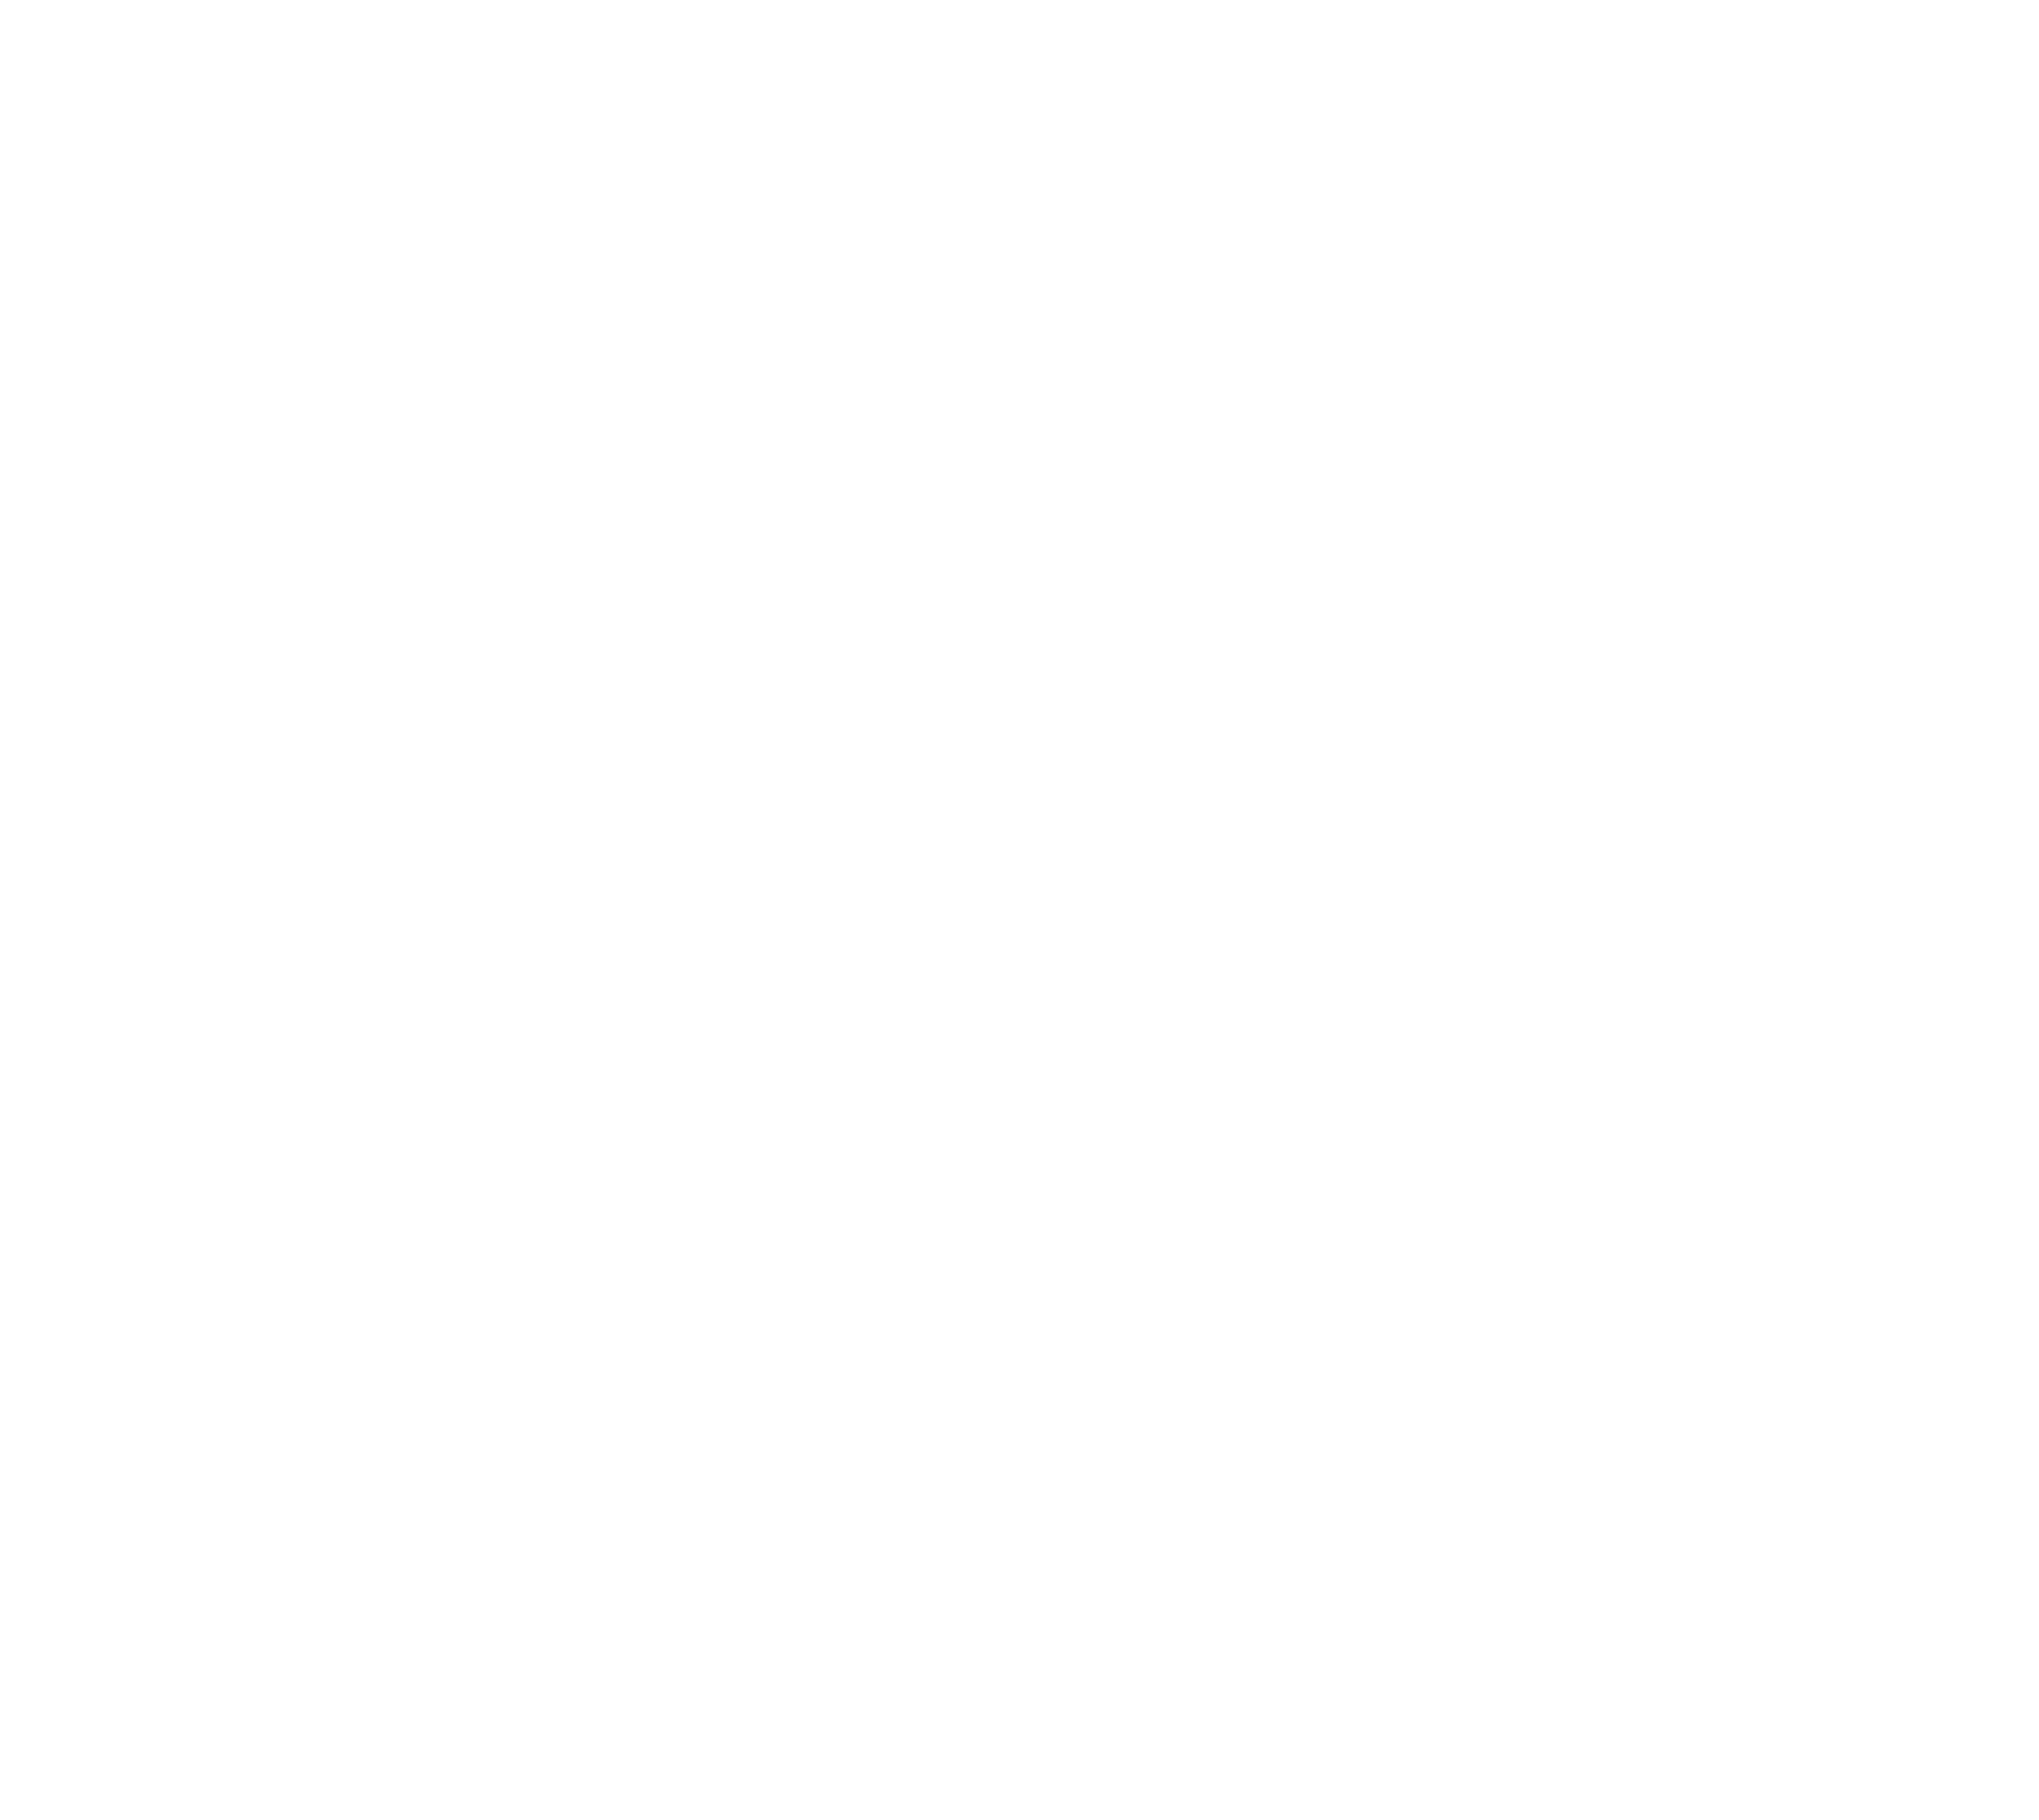

In [5]:
W, H = 2400, 2140
fig = plt.figure(figsize=(W / 100, H / 100), dpi=100)
ax = fig.add_axes([0, 0, 1, 1])
ax.set_xlim(0, W)
ax.set_ylim(H, 0)
ax.axis("off")
fig.patch.set_facecolor("white")
PT = 100 / 72  # px per point


def colourise(img, kind):
    """Map a step output to RGB for a thumbnail."""
    if kind == "rgb":
        return img
    if kind == "labels":
        img = np.asarray(img).astype(int)
        rgb = np.zeros(img.shape + (3,))
        fg = img > 0
        rgb[fg] = LABEL_PALETTE[(img[fg] - 1) % len(LABEL_PALETTE)]
        return rgb
    img = np.asarray(img, float)
    lo, hi = np.percentile(img, [0.5, 99.8])
    img = np.clip((img - lo) / (hi - lo + 1e-9), 0, 1)
    if kind == "binary":
        return np.dstack([img] * 3)
    if kind == "cyan":  # repo's 405 nm LUT
        return np.dstack([np.zeros_like(img), img, img])
    if kind == "magenta":  # repo's 555 nm LUT
        return np.dstack([img, np.zeros_like(img), img])
    return mpl.colormaps["inferno"](img)[..., :3]


# nuclei outlines over the 405 nm image, for the nuclei-mask card
_ov = colourise(S["nuc_clahe"], "cyan") * 0.85
_ov[skimage.segmentation.find_boundaries(S["nuc_labels"], mode="outer")] = (
    1.0,
    0.86,
    0.25,
)
S["nuc_overlay"] = _ov


def thumb(x, y, key, kind="inferno", size=118, caption=None):
    ax.imshow(
        colourise(S[key], kind),
        extent=(x, x + size, y + size, y),
        aspect="auto",
        interpolation="nearest" if kind in ("labels", "binary") else "lanczos",
        zorder=4,
    )
    ax.add_patch(
        Rectangle((x, y), size, size, fill=False, ec="#1B1F24", lw=1.0, zorder=5)
    )
    if caption:
        ax.text(
            x + size / 2,
            y + size + 17,
            caption,
            ha="center",
            va="center",
            fontsize=13,
            style="italic",
            color=MUTED,
            zorder=5,
        )


def panel(x, y, w, h, accent, title, sub, key=None, kind=None):
    acc, tint = ACCENT[accent]
    ax.add_patch(
        FancyBboxPatch(
            (x, y),
            w,
            h,
            boxstyle="round,pad=0,rounding_size=18",
            fc=tint,
            ec=acc,
            lw=2.2,
            zorder=0,
        )
    )
    ax.text(x + 28, y + 52, title, fontsize=28, weight="bold", color=acc, va="center")
    ax.text(x + 28, y + 100, sub, fontsize=16, family=MONO, color=MUTED, va="center")
    if key:
        thumb(x + w - 120 - 26, y + 22, key, kind, 120, "toy input")


def card(
    x,
    y,
    w,
    h,
    accent,
    title,
    lines=(),
    mono=True,
    key=None,
    kind="inferno",
    ts=118,
    cap=None,
    face="white",
    edge=CARD_EDGE,
    title_size=19,
    body_size=15.5,
):
    acc, _ = ACCENT[accent]
    ax.add_patch(
        FancyBboxPatch(
            (x, y),
            w,
            h,
            boxstyle="round,pad=0,rounding_size=12",
            fc=face,
            ec=edge,
            lw=1.6,
            zorder=2,
        )
    )
    ax.add_patch(
        FancyBboxPatch(
            (x + 8, y + 14),
            7,
            h - 28,
            boxstyle="round,pad=0,rounding_size=3.5",
            fc=acc,
            ec="none",
            zorder=3,
        )
    )
    lt, lb = title_size * PT * 1.4, body_size * PT * 1.45
    ty = y + (h - lt - lb * len(lines)) / 2
    ax.text(
        x + 32,
        ty + lt / 2,
        title,
        fontsize=title_size,
        weight="bold",
        color=INK,
        va="center",
        zorder=3,
    )
    ty += lt
    for ln in lines:
        ax.text(
            x + 32,
            ty + lb / 2,
            ln,
            fontsize=body_size,
            va="center",
            color=INK,
            zorder=3,
            family=MONO if mono else None,
        )
        ty += lb
    if key is not None:
        thumb(
            x + w - ts - 18, y + (h - ts) / 2 - (11 if cap else 0), key, kind, ts, cap
        )


def arrow(*pts, color=ARROW, lw=2.2, ls="-"):
    pts = np.asarray(pts, float)
    if len(pts) > 2:
        ax.plot(
            pts[:-1, 0],
            pts[:-1, 1],
            color=color,
            lw=lw,
            ls=ls,
            zorder=1,
            solid_joinstyle="miter",
            solid_capstyle="butt",
        )
    ax.add_patch(
        FancyArrowPatch(
            tuple(pts[-2]),
            tuple(pts[-1]),
            arrowstyle="-|>",
            mutation_scale=20,
            color=color,
            lw=lw,
            ls=ls,
            shrinkA=0,
            shrinkB=0,
            zorder=1,
        )
    )


def dot(x, y, color):
    ax.add_patch(Circle((x, y), 6.5, fc=color, ec="none", zorder=2))

## Layout
Three notebook panels, then cell post-processing (which also consumes the nuclei mask),
cytoplasm and the final masks. Nuclei-mask data lines are drawn in the nuclei accent colour.

In [6]:
NUC = ACCENT["nuclei"][0]
ax.text(
    60,
    62,
    "Cell segmentation  ·  3.cell_segmentation",
    fontsize=34,
    weight="bold",
    color=INK,
    va="center",
)

P0, PB = 130, 1330
ROWS, SH = [330, 526, 722, 918], 150
F0, FH = 1114, 190

# ---- nuclei ------------------------------------------------------------------
nx, nw = 60, 620
panel(
    nx, P0, nw, PB - P0, "nuclei", "Nuclei", "0.segment_nuclei.ipynb", "raw405", "cyan"
)
ncx, ncw = nx + 24, nw - 48
card(
    ncx,
    ROWS[0],
    ncw,
    SH,
    "nuclei",
    "CLAHE (405 nm)",
    ["equalize_adapthist(", "  clip_limit=0.02)"],
    key="nuc_clahe",
    kind="cyan",
)
card(
    ncx,
    ROWS[1],
    ncw,
    SH + 20,
    "nuclei",
    "Cellpose",
    ["CellposeModel(gpu)", "  .eval(nuclei)"],
    key="nuc_labels",
    kind="labels",
    cap="toy stand-in",
)
card(
    ncx,
    F0,
    ncw,
    FH,
    "nuclei",
    "Nuclei mask",
    ["nuclei_mask.tiff", "uint16 labels"],
    key="nuc_overlay",
    kind="rgb",
    ts=150,
    face=ACCENT["nuclei"][1],
    edge=NUC,
)
arrow((ncx + ncw / 2, ROWS[0] + SH), (ncx + ncw / 2, ROWS[1]))
arrow((ncx + ncw / 2, ROWS[1] + SH + 20), (ncx + ncw / 2, F0))

# ---- cells -------------------------------------------------------------------
cx, cw = 720, 1060
panel(
    cx, P0, cw, PB - P0, "cells", "Cells", "1.segment_cells.ipynb", "raw555", "magenta"
)
ccx, ccw = cx + 24, cw - 48
card(
    ccx,
    ROWS[0],
    ccw,
    SH,
    "cells",
    "CLAHE (555 nm)",
    ["equalize_adapthist(clip_limit=0.04)"],
    key="cell_clahe",
    kind="magenta",
)
colw = (ccw - 30) / 2
tx, ex = ccx, ccx + colw + 30
CROWS = [546, 736, 926]
for x, lab in [(tx, "THRESHOLD MASK"), (ex, "ELEVATION MAP")]:
    ax.text(
        x + 4,
        518,
        lab,
        fontsize=15,
        weight="bold",
        color=ACCENT["cells"][0],
        va="center",
    )
    arrow((x + colw / 2, ROWS[0] + SH), (x + colw / 2, CROWS[0]))
for x, rows in [
    (
        tx,
        [
            ("Gaussian blur", ["sigma=3"], "thr_gauss", "inferno"),
            ("Otsu threshold", ["→ binary mask"], "thr_otsu", "binary"),
            ("Dilation", ["disk(1)"], "thr_dil", "binary"),
        ],
    ),
    (
        ex,
        [
            ("Butterworth low-pass", ["cutoff=0.08", "order=2"], "elev_bw", "inferno"),
            ("Gaussian blur", ["sigma=3"], "elev_gauss", "inferno"),
            ("Sobel edges", ["mask = cell > 0"], "elev_sobel", "inferno"),
        ],
    ),
]:
    for r, (t, body, key, kind) in enumerate(rows):
        card(x, CROWS[r], colw, SH, "cells", t, body, key=key, kind=kind)
        nxt = CROWS[r + 1] if r < 2 else F0
        arrow((x + colw / 2, CROWS[r] + SH), (x + colw / 2, nxt))
card(
    ccx,
    F0,
    ccw,
    FH,
    "cells",
    "Watershed",
    [
        "image   = elevation map",
        "markers = nuclei mask",
        "mask    = threshold mask",
        "connectivity=1, compactness=1",
    ],
    key="ws",
    kind="labels",
    ts=160,
)
# nuclei mask → watershed markers
arrow((ncx + ncw, F0 + 125), (ccx, F0 + 125), color=NUC)
ax.text(
    (ncx + ncw + ccx) / 2,
    F0 + 104,
    "markers",
    fontsize=13,
    style="italic",
    color=NUC,
    ha="center",
    va="center",
)

# ---- organoids ---------------------------------------------------------------
ox = cx + cw + 40
ow = 2340 - ox
panel(
    ox,
    P0,
    ow,
    PB - P0,
    "organoids",
    "Organoids",
    "2.segment_organoids.ipynb",
    "raw555",
    "magenta",
)
ocx, ocw = ox + 24, ow - 48
org_steps = [
    ("Gaussian + Otsu", ["sigma=3 → binary"], "org_otsu", "binary"),
    ("Dilation", ["disk(1)"], "org_dil", "binary"),
    ("Fill holes + label", ["binary_fill_holes", "→ ndi.label"], "org_label", "labels"),
    (
        "Per-object cleanup",
        ["remove_small_holes", "closing(disk(3))"],
        "org_clean",
        "labels",
    ),
]
for r, (t, body, key, kind) in enumerate(org_steps):
    card(ocx, ROWS[r], ocw, SH, "organoids", t, body, key=key, kind=kind)
    arrow((ocx + ocw / 2, ROWS[r] + SH), (ocx + ocw / 2, ROWS[r + 1] if r < 3 else F0))
card(
    ocx,
    F0,
    ocw,
    FH,
    "organoids",
    "Size filter",
    ["min_size=500", "organoid_mask.tiff"],
    key="org_final",
    kind="labels",
    ts=150,
    face=ACCENT["organoids"][1],
    edge=ACCENT["organoids"][0],
)

# ---- cell post-processing ----------------------------------------------------
POST = ACCENT["post"][0]
ax.text(
    60,
    1376,
    "Cell post-processing",
    fontsize=24,
    weight="bold",
    color=POST,
    va="center",
)
RW, RH = (2280 - 80) / 3, 170
RX = [60, 60 + RW + 40, 60 + 2 * (RW + 40)]
R1, R2, R3 = 1450, 1680, 1910


def post(i, y, title, body, key, kind="labels", accent="post", **kw):
    card(
        RX[i],
        y,
        RW,
        RH,
        accent,
        title,
        body,
        mono=False,
        key=key,
        kind=kind,
        ts=130,
        title_size=20,
        body_size=16.5,
        **kw,
    )


post(0, R1, "Background reset", ["largest-area label → 0 (twice)"], "bg_reset")
post(1, R1, "Fill holes", ["binary_fill_holes per cell label"], "filled")
post(
    2,
    R1,
    "Support mask",
    ["fill · close disk(3) · ≥ 5,000 px", "keep largest component"],
    "support",
    "binary",
)
post(
    2,
    R2,
    "Gap fill",
    ["empty px inside support ←", "nearest label (distance transform)"],
    "gapfill",
)
post(
    1,
    R2,
    "Size filter",
    ["drop cells and nuclei < 150 px", "clamp cells to support"],
    "clamped",
)
post(
    0,
    R2,
    "Pair with nuclei",
    ["nuclei with no matching cell", "removed from both masks"],
    "paired",
)

# watershed → post-processing (snake: R1 left→right, R2 right→left)
wsx = ccx + ccw / 2
arrow((wsx, F0 + FH), (wsx, 1420), (RX[0] + RW * 0.82, 1420), (RX[0] + RW * 0.82, R1))
arrow((RX[0] + RW, R1 + RH / 2), (RX[1], R1 + RH / 2))
arrow((RX[1] + RW, R1 + RH / 2), (RX[2], R1 + RH / 2))
arrow((RX[2] + RW / 2, R1 + RH), (RX[2] + RW / 2, R2))
arrow((RX[2], R2 + RH / 2), (RX[1] + RW, R2 + RH / 2))
arrow((RX[1], R2 + RH / 2), (RX[0] + RW, R2 + RH / 2))

# ---- cytoplasm and final masks ----------------------------------------------
post(
    0,
    R3,
    "Cytoplasm",
    ["cell − shrunken nucleus", "CellProfiler IdentifyTertiaryObjects"],
    "cyto",
    accent="cells",
)
OUTX, OUTW = RX[1], RX[2] + RW - RX[1]
card(
    OUTX,
    R3,
    OUTW,
    RH,
    "output",
    "Final masks",
    [
        "nuclei, cell and organoid masks (uint16 .tiff)",
        "cytoplasm built at feature extraction",
    ],
    mono=False,
    title_size=20,
    body_size=16.5,
    face=ACCENT["output"][1],
    edge=ACCENT["output"][0],
)
for k, (key, lab) in enumerate(
    [
        ("nuc_final", "nuclei"),
        ("paired", "cell"),
        ("cyto", "cytoplasm"),
        ("org_final", "organoid"),
    ]
):
    thumb(OUTX + OUTW - 4 * 140 - 8 + k * 140, R3 + 14, key, "labels", 118, lab)
arrow((RX[0] + RW / 2, R2 + RH), (RX[0] + RW / 2, R3))
arrow((RX[0] + RW, R3 + RH / 2), (OUTX, R3 + RH / 2))
# organoid branch down the right margin
arrow(
    (ocx + ocw / 2, F0 + FH),
    (ocx + ocw / 2, 1420),
    (2372, 1420),
    (2372, R3 + RH / 2),
    (2340, R3 + RH / 2),
)

# ---- nuclei-mask trunk: feeds size filter, pairing and cytoplasm --------------
TX = 30
ax.plot(
    [ncx, TX, TX], [F0 + FH / 2, F0 + FH / 2, R3 + RH / 2], color=NUC, lw=2.6, zorder=1
)
dot(TX, 1650, NUC)
arrow((TX, 1650), (RX[1] + RW / 2, 1650), (RX[1] + RW / 2, R2), color=NUC, lw=2.6)
dot(TX, R2 + RH / 2, NUC)
arrow((TX, R2 + RH / 2), (RX[0], R2 + RH / 2), color=NUC, lw=2.6)
arrow((TX, R3 + RH / 2 - 0.01), (RX[0], R3 + RH / 2), color=NUC, lw=2.6)
ax.text(
    TX - 14,
    1530,
    "nuclei mask",
    rotation=90,
    fontsize=14,
    style="italic",
    weight="bold",
    color=NUC,
    ha="center",
    va="center",
)

Text(16, 1530, 'nuclei mask')

## Export
PNG raster only, at 600 dpi.

In [7]:
fig.savefig(OUT_DIR / f"{FIG_STEM}.png", dpi=600, facecolor="white")
plt.show()